# Math 32 — Lecture 28: Catch-Up, and What If We Don't Know $\sigma$?

Companion notebook for Lecture 28. Every figure and number in the slides is made here.

**How this notebook is organized.** Every code cell is **self-contained**, so you can change a number
(the data, $n$, the confidence level, the seed, ...) and re-run just that cell.
Figures are saved in a `figures/` folder next to the notebook.

**The setup.** To test our methods, we pretend we know the "true" coffee cart: daily sales with
$\mu = \$300$ and $\sigma = \$32$. In real life we never get to see these — that's the whole point!

## 1. The new cart's first 10 days: the sample standard deviation

We don't know $\sigma$, so we estimate it from the data with the **sample standard deviation**
$$s = \sqrt{\frac{1}{n-1}\sum_{i=1}^n (x_i - \bar x)^2}.$$
`numpy` computes the same thing with `data.std(ddof=1)` — the `ddof=1` means "divide by $n-1$".

**Try it:** change one of the data values to something extreme (like `500`). What happens to $\bar x$ and $s$?

In [1]:
# The new coffee cart: 10 days of data.  Estimate sigma with the sample standard deviation s.
import numpy as np
from math import sqrt

# In real life we don't know these!  We use them only to simulate data and check our methods.
TRUE_MU, TRUE_SIGMA = 300, 32

data = np.array([269, 334, 341, 275, 269, 290, 320, 321, 293, 348])   # 10 days of sales (dollars)
n = len(data)
xbar = data.mean()
dev = data - xbar
s2 = np.sum(dev**2) / (n - 1)          # sample variance: divide by n - 1
s = sqrt(s2)
print("deviations:", dev)
print("sum of squared deviations:", np.sum(dev**2))
print(f"xbar = {xbar},  s^2 = {s2:.2f},  s = {s:.2f}")
print("numpy agrees:", data.mean(), data.var(ddof=1), data.std(ddof=1))

deviations: [-37.  28.  35. -31. -37. -16.  14.  15. -13.  42.]
sum of squared deviations: 8318.0
xbar = 306.0,  s^2 = 924.22,  s = 30.40
numpy agrees: 306.0 924.2222222222222 30.40102337458761


## 2. Three 95% intervals for the new cart

1. $z$ with the **true** $\sigma$ — not available in real life!
2. $z$ with $s$ — tempting, but too narrow on average.
3. $t$ with $s$ — the correct interval when $\sigma$ is unknown. With $n = 10$, there are $9$ degrees of freedom and $t_{9,\,0.025} = 2.262$ (Table B.2).

In [2]:
# Three 95% intervals for the new cart
from math import sqrt
xbar, s, n = 306, 30.40, 10
z, t9 = 1.96, 2.262                     # z_{0.025} and t_{9, 0.025} (Table B.2)
for name, crit, sd in [("z with the TRUE sigma (not available!)", z, 32),
                       ("z with s  (too narrow)", z, s),
                       ("t with s  (correct)", t9, s)]:
    m = crit * sd / sqrt(n)
    print(f"{name:40s} margin = {m:6.2f}   interval = ({xbar - m:.2f}, {xbar + m:.2f})")

z with the TRUE sigma (not available!)   margin =  19.83   interval = (286.17, 325.83)
z with s  (too narrow)                   margin =  18.84   interval = (287.16, 324.84)
t with s  (correct)                      margin =  21.75   interval = (284.25, 327.75)


## 3. Can we just plug in $s$? Checking by simulation

We simulate $100{,}000$ data sets from the "true" coffee cart for several sample sizes $n$, build a "95%" interval from each,
and count how often the interval actually contains $\mu = 300$.

**Try it:** change `sigma` or `mu`. Does the pattern change? (The $t$ critical values are copied from Table B.2.)

n =   3:  z with sigma 0.950   z with s 0.810   t with s 0.950
n =   5:  z with sigma 0.950   z with s 0.879   t with s 0.950
n =  10:  z with sigma 0.950   z with s 0.918   t with s 0.949
n =  30:  z with sigma 0.950   z with s 0.940   t with s 0.949


n =  51:  z with sigma 0.951   z with s 0.945   t with s 0.950


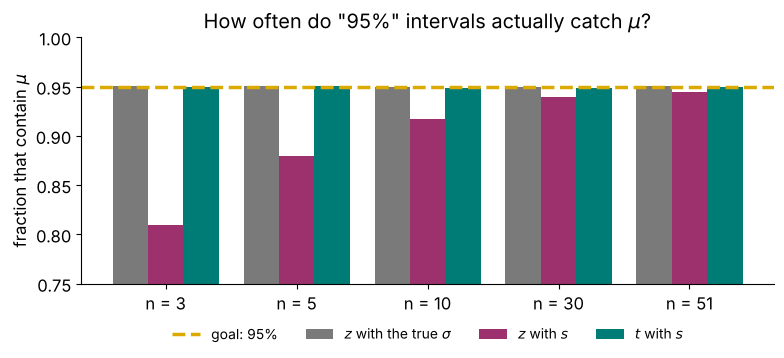

In [3]:
# What goes wrong if we plug s into the z-interval?  Check the coverage by simulation.
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from math import sqrt

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

mu, sigma, reps = 300, 32, 100_000
t_crit = {3: 4.303, 5: 2.776, 10: 2.262, 30: 2.045, 51: 2.009}   # t_{n-1, 0.025} from Table B.2
rng = np.random.default_rng(28)
ns, cov_z_sigma, cov_z_s, cov_t_s = list(t_crit), [], [], []
for n in ns:
    x = rng.normal(mu, sigma, size=(reps, n))
    xbar, s = x.mean(axis=1), x.std(axis=1, ddof=1)
    cov_z_sigma.append(np.mean(np.abs(xbar - mu) <= 1.96 * sigma / sqrt(n)))
    cov_z_s.append(np.mean(np.abs(xbar - mu) <= 1.96 * s / sqrt(n)))
    cov_t_s.append(np.mean(np.abs(xbar - mu) <= t_crit[n] * s / sqrt(n)))
    print(f"n = {n:3d}:  z with sigma {cov_z_sigma[-1]:.3f}   z with s {cov_z_s[-1]:.3f}   t with s {cov_t_s[-1]:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
k = np.arange(len(ns)); w = 0.27
ax.bar(k - w, cov_z_sigma, w, color=GRAY, label=r"$z$ with the true $\sigma$")
ax.bar(k, cov_z_s, w, color=MAGENTA, label=r"$z$ with $s$")
ax.bar(k + w, cov_t_s, w, color=TEAL, label=r"$t$ with $s$")
ax.axhline(0.95, color=GOLD, lw=2.5, ls="--", label="goal: 95%")
ax.set(xticks=k, xticklabels=[f"n = {n}" for n in ns], ylim=(0.75, 1.0), ylabel="fraction that contain $\\mu$",
       title="How often do \"95%\" intervals actually catch $\\mu$?")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=10, ncol=4)
fig.tight_layout()
fig.savefig(OUTDIR / "coverage_z_vs_t.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

## 4. The $t$ distribution

Standardizing with $S$ instead of $\sigma$ gives $T = \dfrac{\bar X_n - \mu}{S/\sqrt n}$, which has a $t(n-1)$ distribution
when the data are normal. It is bell-shaped with **heavier tails** than $N(0,1)$, and gets closer to $N(0,1)$ as $n$ grows.

**Try it:** change `n` to `30`. How close are the histogram, the $N(0,1)$ curve, and the $t(n-1)$ curve now?
(You'll also need to change `t_density(zz, 4)` to `t_density(zz, n - 1)`.)

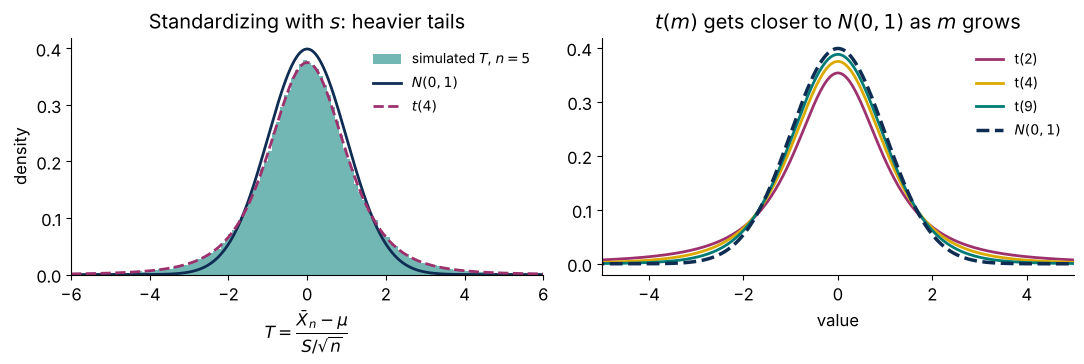

P(|T| > 1.96) in the simulation: 0.12157  (would be 0.05 for N(0,1))


In [4]:
# Using s instead of sigma makes the standardized average spread out more: the t distribution
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from math import sqrt, pi, gamma

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

def t_density(x, m):                    # density of the t distribution with m degrees of freedom
    return gamma((m + 1) / 2) / (sqrt(m * pi) * gamma(m / 2)) * (1 + x**2 / m) ** (-(m + 1) / 2)

mu, sigma, n, reps = 300, 32, 5, 200_000
x = np.random.default_rng(5).normal(mu, sigma, size=(reps, n))
xbar, s = x.mean(axis=1), x.std(axis=1, ddof=1)
T = (xbar - mu) / (s / sqrt(n))         # standardize with s instead of sigma

zz = np.linspace(-6, 6, 600)
phi = np.exp(-zz**2 / 2) / sqrt(2 * pi)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].hist(T, bins=120, range=(-6, 6), density=True, color=TEAL, alpha=0.55, label=r"simulated $T$, $n=5$")
axs[0].plot(zz, phi, color=NAVY, lw=2, label=r"$N(0,1)$")
axs[0].plot(zz, t_density(zz, 4), color=MAGENTA, lw=2, ls="--", label=r"$t(4)$")
axs[0].set(xlim=(-6, 6), xlabel=r"$T = \dfrac{\bar X_n - \mu}{S/\sqrt{n}}$", ylabel="density",
           title=r"Standardizing with $s$: heavier tails")
axs[0].legend(frameon=False, fontsize=10)
for m, col, lab in [(2, MAGENTA, "t(2)"), (4, GOLD, "t(4)"), (9, TEAL, "t(9)")]:
    axs[1].plot(zz, t_density(zz, m), color=col, lw=2, label=lab)
axs[1].plot(zz, phi, color=NAVY, lw=2.5, ls="--", label=r"$N(0,1)$")
axs[1].set(xlim=(-5, 5), xlabel="value", title=r"$t(m)$ gets closer to $N(0,1)$ as $m$ grows")
axs[1].legend(frameon=False, fontsize=10)
fig.tight_layout()
fig.savefig(OUTDIR / "t_distribution.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()
print("P(|T| > 1.96) in the simulation:", np.mean(np.abs(T) > 1.96), " (would be 0.05 for N(0,1))")